In [306]:
import numpy as np
from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d
from scipy import constants
import matplotlib.pyplot as plt
MP2 = 1
def omega_r(h):
    ab = (8*constants.pi**5*constants.k**4)/(15*constants.h**3*constants.c**3)
    rhor = ab*2.7255**4/(constants.c**2)
    rhov = 3.046*(7/8)*(4/11)**(4/3)*rhor
    return((rhor+rhov)/((3*(100*h)**2/(8*constants.pi*constants.G))*(1000)**2/(10**6*constants.parsec)**2))

#power series for a and cp(varpi)
def aseries(tau, cpr, omega_m, h, OmL, a0, stigma, mups2):
    val = (
        (200*h*(omega_r(h))**(1/2)*(stigma)**(1/2)*(-cpr**2 + \
        stigma)**(1/2)*tau)/(a0*cpr*(mups2)**(1/2)*(cpr**2 - 5*stigma + 4*(2 - \
        cpr**2)*stigma**2)**(1/2)) - (5000*h**2*(2*cpr**2*(-4 + stigma)*(-1 + \
        stigma)*stigma**3 + stigma**4 - 2*stigma**5 + 2*cpr**4*stigma**2*(2 + \
        stigma)*(-3 + 4*stigma) + 2*cpr**6*stigma*(2 + stigma - 7*stigma**2) + \
        cpr**8*(-1 + \
        4*stigma**2))*tau**2*(omega_m))/(a0*cpr**2*mups2*(stigma**3*(5 + \
        stigma)*(-1 + 2*stigma) + cpr**6*(-1 + 2*stigma)*(1 + 2*stigma)*(-2 + \
        3*(-1 + stigma)*stigma) + 3*cpr**2*stigma**2*(8 + stigma*(-17 + \
        3*stigma)) - cpr**4*stigma*(11 + stigma + 2*stigma**2*(-30 + \
        stigma*(14 + stigma))))) + (62500*h**3*(stigma)**(1/2)*(-cpr**2 + \
        stigma)**(3/2)*(cpr**2 - stigma*(5 + 4*(-2 + \
        cpr**2)*stigma))**(1/2)*(-12*cpr**18*(-1 + stigma)*(-1 + \
        4*stigma**2)**3 + stigma**8*(38 + stigma*(-287 + 4*stigma*(103 + (17 - \
        24*stigma)*stigma))) + cpr**16*(1 - 4*stigma**2)**2*(18 + stigma*(111 \
        + 2*stigma*(-107 + stigma*(-59 + 109*stigma)))) + \
        2*cpr**2*stigma**7*(99 + stigma*(375 + stigma*(-1187 + stigma*(37 + \
        4*(43 - 9*stigma)*stigma)))) + 2*cpr**4*stigma**6*(-1632 + \
        stigma*(4497 + stigma*(-4915 + stigma*(5505 + stigma*(-1215 + \
        14*stigma*(-43 + 18*stigma)))))) - 2*cpr**14*stigma*(-1 + \
        2*stigma)*(1 + 2*stigma)*(-93 + stigma*(-125 + stigma*(1081 + \
        stigma*(475 + 2*stigma*(-1547 + 2*stigma*(421 + 63*stigma)))))) + \
        2*cpr**6*stigma**5*(1889 + stigma*(221 + stigma*(-14701 + \
        stigma*(19921 + 2*stigma*(-7251 + 2*stigma*(711 + (188 - \
        51*stigma)*stigma)))))) + 2*cpr**8*stigma**4*(-648 + stigma*(-4704 + \
        stigma*(10957 + stigma*(13373 + stigma*(-33001 + 4*stigma*(5742 + \
        stigma*(-889 + stigma*(-175 + 9*stigma)))))))) + \
        2*cpr**10*stigma**3*(-399 + stigma*(3727 + stigma*(1965 + \
        stigma*(-24061 + 4*stigma*(2735 + stigma*(5248 + stigma*(-5021 + \
        stigma*(699 + 86*stigma)))))))) - 2*cpr**12*stigma**2*(-340 + \
        stigma*(569 + stigma*(5253 + stigma*(-7943 + stigma*(-14915 + \
        2*stigma*(11863 + 2*stigma*(-164 + stigma*(-2183 + \
        287*stigma)))))))))*tau**3*(omega_m)**2)/(a0*cpr**3*mups2**(3/2)*(omega_r(h))**(1/2)*(stigma**3*(5 + \
        stigma)*(-1 + 2*stigma) + cpr**6*(-1 + 2*stigma)*(1 + 2*stigma)*(-2 + \
        3*(-1 + stigma)*stigma) + 3*cpr**2*stigma**2*(8 + stigma*(-17 + \
        3*stigma)) - cpr**4*stigma*(11 + stigma + 2*stigma**2*(-30 + \
        stigma*(14 + stigma))))**2*(stigma**3*(16 - stigma*(23 + 20*stigma)) + \
        cpr**2*stigma**2*(-57 + 2*stigma*(41 - 7*(-5 + stigma)*stigma)) - \
        3*cpr**6*(3 + 2*stigma*(1 + stigma)*(1 + 4*(-2 + stigma)*stigma)) + \
        cpr**4*stigma*(36 + stigma*(3 + 2*stigma*(-88 + stigma*(23 + 5*stigma))))))
    )
    return val

def cpseries(tau, cpr, omega_m, h, OmL, a0, stigma, mups2):
    val = (
        cpr + (25*h*(-cpr**2 + stigma)**(3/2)*(cpr**2 - stigma*(5 + 4*(-2 + \
        cpr**2)*stigma))**(1/2)*((5 - 2*stigma)*stigma**2 + \
        2*cpr**2*stigma*(1 + (-5 + stigma)*stigma) + cpr**4*(-1 + \
        4*stigma**2))*tau*(omega_m))/((mups2)**(1/2)*(omega_r(h))**(1/2)*(stigma)**(1/2)*(stigma**3*(5 + \
        stigma)*(-1 + 2*stigma) + cpr**6*(-1 + 2*stigma)*(1 + 2*stigma)*(-2 + \
        3*(-1 + stigma)*stigma) + 3*cpr**2*stigma**2*(8 + stigma*(-17 + \
        3*stigma)) - cpr**4*stigma*(11 + stigma + 2*stigma**2*(-30 + \
        stigma*(14 + stigma))))) + (1875*h**2*(-cpr**2 + stigma)**2*(-cpr**2 + \
        stigma*(5 + 4*(-2 + cpr**2)*stigma))*(6*cpr**16*(-1 + 4*stigma**2)**3 \
        + stigma**8*(-1 + 2*stigma)*(-50 + stigma*(-61 + 2*stigma*(-11 + \
        8*stigma))) + cpr**14*stigma*(1 - 4*stigma**2)**2*(48 + stigma*(-35 + \
        6*stigma*(-19 + (-3 + stigma)*stigma))) + cpr**2*stigma**7*(-922 + \
        stigma*(2351 + 2*stigma*(-597 + stigma*(43 + 4*(55 - \
        13*stigma)*stigma)))) - cpr**12*stigma**2*(-1 + 2*stigma)*(1 + \
        2*stigma)*(-214 + stigma*(323 + 2*stigma*(596 + stigma*(-626 + \
        stigma*(-439 + 16*stigma*(-3 + 2*stigma)))))) + \
        cpr**4*stigma**6*(1330 + stigma*(-203 + 2*stigma*(-4108 + \
        stigma*(3664 + stigma*(-491 + 10*stigma*(-35 + 6*stigma)))))) + \
        cpr**6*stigma**5*(-508 + stigma*(-3781 + 2*stigma*(4661 + \
        stigma*(3573 + stigma*(-7349 + 2*stigma*(739 + 2*(39 - \
        7*stigma)*stigma)))))) + cpr**10*stigma**3*(574 - stigma*(2119 + \
        2*stigma*(1383 + stigma*(-5397 + 2*stigma*(-763 + stigma*(2473 + \
        2*stigma*(509 + (-153 + stigma)*stigma))))))) + \
        cpr**8*stigma**4*(-512 + stigma*(4783 + 4*stigma*(-787 + \
        stigma*(-3513 + stigma*(1301 + stigma*(3051 + 2*stigma*(-366 + \
        stigma*(2 + \
        stigma)))))))))*tau**2*(omega_m)**2)/(2*cpr*mups2*omega_r(h)*stigma*(stigma**3*(5 + stigma)*(-1 + 2*stigma) \
        + cpr**6*(-1 + 2*stigma)*(1 + 2*stigma)*(-2 + 3*(-1 + stigma)*stigma) \
        + 3*cpr**2*stigma**2*(8 + stigma*(-17 + 3*stigma)) - \
        cpr**4*stigma*(11 + stigma + 2*stigma**2*(-30 + stigma*(14 + \
        stigma))))**2*(stigma**3*(16 - stigma*(23 + 20*stigma)) + \
        cpr**2*stigma**2*(-57 + 2*stigma*(41 - 7*(-5 + stigma)*stigma)) - \
        3*cpr**6*(3 + 2*stigma*(1 + stigma)*(1 + 4*(-2 + stigma)*stigma)) + \
        cpr**4*stigma*(36 + stigma*(3 + 2*stigma*(-88 + stigma*(23 + 5*stigma))))))
    )
    return val


def aseriesp(tau, cpr, omega_m, h, OmL, a0, stigma, mups2):
    val = (
        (200*h*(omega_r(h))**(1/2)*(stigma)**(1/2)*(-cpr**2 + \
        stigma)**(1/2))/(a0*cpr*(mups2)**(1/2)*(cpr**2 - 5*stigma + 4*(2 - \
        cpr**2)*stigma**2)**(1/2)) - (10000*h**2*(2*cpr**2*(-4 + stigma)*(-1 + \
        stigma)*stigma**3 + stigma**4 - 2*stigma**5 + 2*cpr**4*stigma**2*(2 + \
        stigma)*(-3 + 4*stigma) + 2*cpr**6*stigma*(2 + stigma - 7*stigma**2) + \
        cpr**8*(-1 + \
        4*stigma**2))*tau*(omega_m))/(a0*cpr**2*mups2*(stigma**3*(5 + \
        stigma)*(-1 + 2*stigma) + cpr**6*(-1 + 2*stigma)*(1 + 2*stigma)*(-2 + \
        3*(-1 + stigma)*stigma) + 3*cpr**2*stigma**2*(8 + stigma*(-17 + \
        3*stigma)) - cpr**4*stigma*(11 + stigma + 2*stigma**2*(-30 + \
        stigma*(14 + stigma))))) + (187500*h**3*(stigma)**(1/2)*(-cpr**2 + \
        stigma)**(3/2)*(cpr**2 - stigma*(5 + 4*(-2 + \
        cpr**2)*stigma))**(1/2)*(-12*cpr**18*(-1 + stigma)*(-1 + \
        4*stigma**2)**3 + stigma**8*(38 + stigma*(-287 + 4*stigma*(103 + (17 - \
        24*stigma)*stigma))) + cpr**16*(1 - 4*stigma**2)**2*(18 + stigma*(111 \
        + 2*stigma*(-107 + stigma*(-59 + 109*stigma)))) + \
        2*cpr**2*stigma**7*(99 + stigma*(375 + stigma*(-1187 + stigma*(37 + \
        4*(43 - 9*stigma)*stigma)))) + 2*cpr**4*stigma**6*(-1632 + \
        stigma*(4497 + stigma*(-4915 + stigma*(5505 + stigma*(-1215 + \
        14*stigma*(-43 + 18*stigma)))))) - 2*cpr**14*stigma*(-1 + \
        2*stigma)*(1 + 2*stigma)*(-93 + stigma*(-125 + stigma*(1081 + \
        stigma*(475 + 2*stigma*(-1547 + 2*stigma*(421 + 63*stigma)))))) + \
        2*cpr**6*stigma**5*(1889 + stigma*(221 + stigma*(-14701 + \
        stigma*(19921 + 2*stigma*(-7251 + 2*stigma*(711 + (188 - \
        51*stigma)*stigma)))))) + 2*cpr**8*stigma**4*(-648 + stigma*(-4704 + \
        stigma*(10957 + stigma*(13373 + stigma*(-33001 + 4*stigma*(5742 + \
        stigma*(-889 + stigma*(-175 + 9*stigma)))))))) + \
        2*cpr**10*stigma**3*(-399 + stigma*(3727 + stigma*(1965 + \
        stigma*(-24061 + 4*stigma*(2735 + stigma*(5248 + stigma*(-5021 + \
        stigma*(699 + 86*stigma)))))))) - 2*cpr**12*stigma**2*(-340 + \
        stigma*(569 + stigma*(5253 + stigma*(-7943 + stigma*(-14915 + \
        2*stigma*(11863 + 2*stigma*(-164 + stigma*(-2183 + \
        287*stigma)))))))))*tau**2*(omega_m)**2)/(a0*cpr**3*mups2**(3/2)*(omega_r(h))**(1/2)*(stigma**3*(5 + \
        stigma)*(-1 + 2*stigma) + cpr**6*(-1 + 2*stigma)*(1 + 2*stigma)*(-2 + \
        3*(-1 + stigma)*stigma) + 3*cpr**2*stigma**2*(8 + stigma*(-17 + \
        3*stigma)) - cpr**4*stigma*(11 + stigma + 2*stigma**2*(-30 + \
        stigma*(14 + stigma))))**2*(stigma**3*(16 - stigma*(23 + 20*stigma)) + \
        cpr**2*stigma**2*(-57 + 2*stigma*(41 - 7*(-5 + stigma)*stigma)) - \
        3*cpr**6*(3 + 2*stigma*(1 + stigma)*(1 + 4*(-2 + stigma)*stigma)) + \
        cpr**4*stigma*(36 + stigma*(3 + 2*stigma*(-88 + stigma*(23 + 5*stigma))))))
    )
    return val


def cpseriesp(tau, cpr, omega_m, h, OmL, a0, stigma, mups2):
    val = (
        (25*h*(-cpr**2 + stigma)**(3/2)*(cpr**2 - stigma*(5 + 4*(-2 + \
        cpr**2)*stigma))**(1/2)*((5 - 2*stigma)*stigma**2 + \
        2*cpr**2*stigma*(1 + (-5 + stigma)*stigma) + cpr**4*(-1 + \
        4*stigma**2))*(omega_m))/((mups2)**(1/2)*(omega_r(h))**(1/2)*(stigma)**(1/2)*(stigma**3*(5 + \
        stigma)*(-1 + 2*stigma) + cpr**6*(-1 + 2*stigma)*(1 + 2*stigma)*(-2 + \
        3*(-1 + stigma)*stigma) + 3*cpr**2*stigma**2*(8 + stigma*(-17 + \
        3*stigma)) - cpr**4*stigma*(11 + stigma + 2*stigma**2*(-30 + \
        stigma*(14 + stigma))))) + (1875*h**2*(-cpr**2 + stigma)**2*(-cpr**2 + \
        stigma*(5 + 4*(-2 + cpr**2)*stigma))*(6*cpr**16*(-1 + 4*stigma**2)**3 \
        + stigma**8*(-1 + 2*stigma)*(-50 + stigma*(-61 + 2*stigma*(-11 + \
        8*stigma))) + cpr**14*stigma*(1 - 4*stigma**2)**2*(48 + stigma*(-35 + \
        6*stigma*(-19 + (-3 + stigma)*stigma))) + cpr**2*stigma**7*(-922 + \
        stigma*(2351 + 2*stigma*(-597 + stigma*(43 + 4*(55 - \
        13*stigma)*stigma)))) - cpr**12*stigma**2*(-1 + 2*stigma)*(1 + \
        2*stigma)*(-214 + stigma*(323 + 2*stigma*(596 + stigma*(-626 + \
        stigma*(-439 + 16*stigma*(-3 + 2*stigma)))))) + \
        cpr**4*stigma**6*(1330 + stigma*(-203 + 2*stigma*(-4108 + \
        stigma*(3664 + stigma*(-491 + 10*stigma*(-35 + 6*stigma)))))) + \
        cpr**6*stigma**5*(-508 + stigma*(-3781 + 2*stigma*(4661 + \
        stigma*(3573 + stigma*(-7349 + 2*stigma*(739 + 2*(39 - \
        7*stigma)*stigma)))))) + cpr**10*stigma**3*(574 - stigma*(2119 + \
        2*stigma*(1383 + stigma*(-5397 + 2*stigma*(-763 + stigma*(2473 + \
        2*stigma*(509 + (-153 + stigma)*stigma))))))) + \
        cpr**8*stigma**4*(-512 + stigma*(4783 + 4*stigma*(-787 + \
        stigma*(-3513 + stigma*(1301 + stigma*(3051 + 2*stigma*(-366 + \
        stigma*(2 + \
        stigma)))))))))*tau*(omega_m)**2)/(cpr*mups2*omega_r(h)*stigma*(stigma**3*(5 \
        + stigma)*(-1 + 2*stigma) + cpr**6*(-1 + 2*stigma)*(1 + 2*stigma)*(-2 \
        + 3*(-1 + stigma)*stigma) + 3*cpr**2*stigma**2*(8 + stigma*(-17 + \
        3*stigma)) - cpr**4*stigma*(11 + stigma + 2*stigma**2*(-30 + \
        stigma*(14 + stigma))))**2*(stigma**3*(16 - stigma*(23 + 20*stigma)) + \
        cpr**2*stigma**2*(-57 + 2*stigma*(41 - 7*(-5 + stigma)*stigma)) - \
        3*cpr**6*(3 + 2*stigma*(1 + stigma)*(1 + 4*(-2 + stigma)*stigma)) + \
        cpr**4*stigma*(36 + stigma*(3 + 2*stigma*(-88 + stigma*(23 + 5*stigma))))))
    )
    return val


In [307]:
aseries(1e-9, 0.999, 0.3, 0.7, 0.7, 1, 1.2, 4/3)

6.294081763647791e-10

In [308]:
cpseries(1e-9, 0.999, 0.3, 0.7, 0.7, 1, 1.2, 4/3)

0.9989997315413324

In [309]:
def P_deriveda0(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, mups2):
    return((MP2*(10000*cp**9*da*h**2*(-1 + 4*stigma**2)**3*(4*a**4*a0**4*OmL + \
            mups2*omega_r(h) + a*a0*(omega_m)) + 2*a*dcp*stigma**3*(-1 + 2*stigma)*(1 + \
            2*stigma)*(-7 + 4*stigma)*(a**2*a0**2*dcp**2*mups2 + \
            40000*h**2*stigma*(a**4*a0**4*OmL + omega_r(h) + a*a0*(omega_m))) + \
            2*a*cp**6*dcp*(1 - 4*stigma**2)**2*(a**2*a0**2*dcp**2*mups2*(1 - \
            4*stigma**2) + 40000*h**2*stigma*(a**4*a0**4*OmL + omega_r(h) + \
            a*a0*(omega_m))) - 2*a*cp**2*dcp*stigma**2*(-1 + \
            4*stigma**2)*(-(a**2*a0**2*dcp**2*mups2*(5 + 8*stigma*(1 + 2*(-2 + \
            stigma)*stigma))) + 40000*h**2*stigma*(-5 + 2*stigma)*(1 + \
            2*stigma)*(a**4*a0**4*OmL + omega_r(h) + a*a0*(omega_m))) + \
            2*a*cp**4*dcp*stigma*(-(a**2*a0**2*dcp**2*mups2*(3 + 4*(-3 + \
            stigma)*stigma)*(1 - 4*stigma**2)**2) - 120000*h**2*stigma*(-1 + \
            2*stigma)*(1 + 2*stigma)*(-1 + 4*stigma)*(a**4*a0**4*OmL + omega_r(h) + \
            a*a0*(omega_m))) + cp*da*stigma**3*(-(a**2*a0**2*dcp**2*mups2*(-1 + \
            2*stigma)*(1 + 2*stigma)*(43 + 8*stigma*(-19 + 8*stigma))) - \
            10000*h**2*stigma*(-5 + 8*stigma)*(8*a**4*a0**4*OmL*(-1 + stigma)*(1 + \
            2*stigma) + 4*omega_r(h)*(3 + 2*stigma*(-5 + 2*stigma)) + a*a0*(-7 + \
            4*stigma)*(-1 + 4*stigma)*(omega_m))) - cp**7*da*(1 - \
            4*stigma**2)**2*(3*a**2*a0**2*dcp**2*mups2*(-1 + 4*stigma**2) + \
            10000*h**2*stigma*(4*a**4*a0**4*OmL*(-11 + 2*stigma*(9 + stigma)) + \
            omega_r(h)*(4 - 8*(-1 + stigma)*stigma + mups2*(-11 + 4*stigma*(4 + stigma))) \
            - 4*a*a0*(2 + (-6 + stigma)*stigma)*(omega_m))) + \
            cp**3*da*stigma**2*(10000*h**2*omega_r(h)*stigma*(-92 - mups2*(5 - \
            8*stigma)**2*(-1 + 4*stigma**2) + 8*stigma*(21 + stigma*(69 + \
            4*stigma*(-41 + 18*stigma)))) + a*a0*(a*a0*dcp**2*mups2*(-1 + \
            2*stigma)*(1 + 2*stigma)*(43 + 8*stigma*(-1 + stigma*(-31 + 12*stigma))) \
            + 40000*h**2*stigma*(a**3*a0**3*OmL*(37 + 2*stigma*(-67 + 7*stigma*(9 \
            + 4*stigma - 8*stigma**2))) + (-2 + 5*stigma)*(4 + stigma*(11 + \
            8*stigma*(-5 + 2*stigma)))*(omega_m)))) + cp**5*da*stigma*(-1 + \
            4*stigma**2)*(10000*h**2*omega_r(h)*stigma*(mups2*(-5 + 8*stigma)*(-7 + \
            8*stigma*(1 + stigma)) - 4*(9 + 2*stigma*(1 + 2*stigma*(-13 + \
            8*stigma)))) + a*a0*(3*a*a0*dcp**2*mups2*(1 - 16*(stigma - \
            4*stigma**3 + stigma**4)) + 20000*h**2*stigma*(2*a**3*a0**3*OmL*(37 + \
            2*stigma*(-57 + 4*stigma*(9 + 4*stigma))) + (5 - 2*stigma*(30 + \
            stigma*(-57 + \
            16*stigma)))*(omega_m))))))/(a**4*cp**3*da*mups2*(-cp**2 + \
            stigma)*(-1 + 4*stigma**2)*((5 - 8*stigma)*stigma + cp**2*(-1 + \
            4*stigma**2))**2))
    
def rho_deriveda0(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, mups2):
    return((3*MP2*(-10000*h**2*omega_r(h) - 10000*a*h**2*(omega_m) + \
            (-(a**2*a0**2*dcp**2*mups2*(-stigma + cp**2*(1 - 4*stigma**2))) - \
            2*a*a0**2*cp*da*dcp*mups2*(stigma*(-1 + 4*stigma) + cp**2*(1 - \
            4*stigma**2)) + 40000*h**2*stigma*(-cp**2 + stigma)*(a**4*a0**4*OmL \
            + omega_r(h) + a*a0*(omega_m)))/(-(cp**2*mups2*(5 - 8*stigma)*stigma) - \
            cp**4*mups2*(-1 + 4*stigma**2))))/a**4)



In [310]:
def ddcp(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, mups2):
    val = (-1/8*(120000*a**4*a0**4*h**2*OmL*stigma*(-cp**2 + \
            stigma)**2*(stigma - 4*stigma**2 + cp**2*(-1 + 4*stigma**2)) - \
            40000*h**2*omega_r(h)*stigma*(-cp**2 + stigma)**2*(stigma - 4*stigma**2 + \
            cp**2*(-1 + 4*stigma**2)) + a0**2*cp**2*da**2*mups2*((5 - \
            8*stigma)*stigma + cp**2*(-1 + 4*stigma**2))*((7 - \
            4*stigma)*stigma**2 + 2*cp**2*stigma*(1 + 2*(-3 + stigma)*stigma) + \
            cp**4*(-1 + 4*stigma**2)) + a**2*a0**2*dcp**2*mups2*(stigma**3*(-1 + \
            4*stigma)*(1 + 8*stigma) + cp**4*stigma*(-1 + 2*stigma)*(1 + \
            2*stigma)*(3 + 4*(-3 + stigma)*stigma) + cp**6*(1 - 4*stigma**2)**2 + \
            cp**2*stigma**2*(3 - 8*(stigma + 2*stigma**3))) + \
            2*a*a0**2*cp*da*dcp*mups2*(cp**4*stigma*(-1 + 2*stigma)*(1 + \
            2*stigma)*(11 + 4*(-4 + stigma)*stigma) + cp**6*(1 - 4*stigma**2)**2 + \
            stigma**3*(-1 + 16*stigma*(-2 + 3*stigma)) + cp**2*stigma**2*(11 - \
            16*stigma*(1 + stigma*(-1 + \
            2*stigma)))))/(a**2*a0**2*cp*mups2*stigma*(-cp**2 + stigma)**2*(-1 + \
            4*stigma**2)))
    return val

def dda(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, mups2):
    val = (-1/8*(-(a**2*a0**2*dcp**2*mups2*(3*cp**2*stigma**2 + cp**4*(1 - \
            2*stigma)**2*stigma*(-3 + 2*stigma)*(1 + 2*stigma) - stigma**3*(1 + \
            8*stigma) + cp**6*(1 - 4*stigma**2)**2)) - \
            120000*a**4*a0**4*h**2*OmL*stigma*(-cp**2 + stigma)**2*(stigma + \
            cp**2*(-1 + 4*stigma**2)) + 40000*h**2*omega_r(h)*stigma*(-cp**2 + \
            stigma)**2*(stigma + cp**2*(-1 + 4*stigma**2)) - \
            2*a*a0**2*cp*da*dcp*mups2*(stigma + cp**2*(-1 + 4*stigma**2))*((7 - \
            4*stigma)*stigma**2 + 2*cp**2*stigma*(1 + 2*(-3 + stigma)*stigma) + \
            cp**4*(-1 + 4*stigma**2)) - a0**2*cp**2*da**2*mups2*(cp**4*(1 - \
            2*stigma)**2*stigma*(-7 + 2*stigma)*(1 + 2*stigma) + stigma**3*(3 + \
            32*(-1 + stigma)*stigma) + cp**6*(1 - 4*stigma**2)**2 + \
            cp**2*stigma**2*(3 - 16*(-1 + stigma)*stigma*(-1 + \
            2*stigma))))/(a*a0**2*cp**2*mups2*stigma*(-cp**2 + stigma)**2*(-1 + \
            4*stigma**2)))
    return val


In [311]:
def constraint(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, mups2):
    val = ((3*a*a0*MP2*((-2*cp*da*dcp*mups2)/a - dcp**2*mups2 - (4*(((-1 + \
            cp**2)*da)/a + cp*dcp)**2*mups2*stigma**2)/(-cp**2 + stigma) + \
            (da**2*mups2*(-cp**2 + 4*stigma))/a**2 - \
            (40000*h**2*stigma*(a**4*a0**4*OmL + omega_r(h) + \
            a*a0*(omega_m)))/(a**2*a0**2)))/(4*stigma))
    # val = ((-2*cp*da*dcp*mups2)/a - dcp**2*mups2 - (4*(((-1 + cp**2)*da)/a + \
    #         cp*dcp)**2*mups2*stigma**2)/(-cp**2 + stigma) + (da**2*mups2*(-cp**2 + \
    #         4*stigma))/a**2 - (40000*h**2*stigma*(a**4*a0**4*OmL + omega_r(h) + \
    #         a*a0*(omega_m)))/(a**2*a0**2))
    return val

In [312]:
def constraint_ratio(a, da, cp, a0, stigma, mups2):
    T_hd = 3*a*a0*MP2/(4*stigma) * \
           (da**2*mups2*(-cp**2 + 4*stigma))/a**2
    return T_hd

In [313]:
def G(a, da, cp, dcp, stigma, mups, a0):
    val = (-4*a0**4*da**2*stigma*(-cp**2 + stigma))/(mups2*(-(cp**4*da**2) - 2*a*cp**3*da*dcp - a**2*cp**2*dcp**2 + 5*cp**2*da**2*stigma + 2*a*cp*da*dcp*stigma + a**2*dcp**2*stigma - 8*cp**2*da**2*stigma**2 + 4*cp**4*da**2*stigma**2 - 8*a*cp*da*dcp*stigma**2 + 8*a*cp**3*da*dcp*stigma**2 + 4*a**2*cp**2*dcp**2*stigma**2)) 
    return val

In [412]:
small(0.9, 0.3, 0.7, 1.01, 4/3)

np.float64(1.8137398140777718e-07)

In [422]:
def weff2(a, cp, da, dcp, dda, ddcp, mups2, stigma, h, omega_m):
    return (((2*a**2*dcp)/cp + (2*a**2*cp*dcp*(-1 + 4*stigma**2))/((5 - \
        8*stigma)*stigma + cp**2*(-1 + 4*stigma**2)) + \
        (da*(120000*a**4*a0**4*h**2*OmL*(cp**2 - stigma)*stigma + \
        40000*h**2*omega_r(h)*stigma*(-cp**2 + stigma) - \
        a**2*a0**2*mups2*(2*cp*ddcp*(stigma - 4*stigma**2 + cp**2*(-1 + \
        4*stigma**2)) + dcp**2*((3 - 8*stigma)*stigma + 7*cp**2*(-1 + \
        4*stigma**2)))) + 2*a*dcp*(-(a**2*a0**2*ddcp*mups2*(stigma + \
        cp**2*(-1 + 4*stigma**2))) + cp*(40000*h**2*omega_r(h)*stigma + \
        a*a0*(40000*a**3*a0**3*h**2*OmL*stigma - a*a0*dcp**2*mups2*(-1 + \
        4*stigma**2) - a0*dda*mups2*(stigma - 4*stigma**2 + cp**2*(-1 + \
        4*stigma**2)) + \
        40000*h**2*stigma*(omega_m)))))/(a0**2*(-2*cp*da*dcp*mups2*(stigma*(-1 + 4*stigma) + cp**2*(1 - \
        4*stigma**2)) + a*dcp**2*mups2*(stigma + cp**2*(-1 + 4*stigma**2)) + \
        (40000*h**2*stigma*(-cp**2 + stigma)*(a**4*a0**4*OmL + omega_r(h) + \
        a*a0*(omega_m)))/(a*a0**2))))/(3*a*da))

In [439]:
def coupdiff(y, tau, omega_m, h, OmL, a0, stigma, mups2):
    a, cp, da, dcp = y
    dydt = [da, dcp, dda(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, mups2), ddcp(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, mups2)]
    return dydt

#Initial conditions
def small(cpr, omega_m, h, stigma, mups2):
    val = (np.abs((cpr*(stigma**3*(5 + stigma)*(-1 + 2*stigma) + cpr**6*(-1 + 
			2*stigma)*(1 + 2*stigma)*(-2 + 3*(-1 + stigma)*stigma) + 
			3*cpr**2*stigma**2*(8 + stigma*(-17 + 3*stigma)) - cpr**4*stigma*(11 + 
			stigma + 2*stigma**2*(-30 + stigma*(14 + 
			stigma))))*((omega_r(h)*stigma*(-cpr**2 + stigma)*-mups2)/(-cpr**2 + 
			5*stigma + 4*(-2 + cpr**2)*stigma**2))**(1/2))/(h*(2*cpr**2*(-4 + 
			stigma)*(-1 + stigma)*stigma**3 + stigma**4 - 2*stigma**5 + 
			2*cpr**4*stigma**2*(2 + stigma)*(-3 + 4*stigma) + 2*cpr**6*stigma*(2 + 
			stigma - 7*stigma**2) + cpr**8*(-1 + 
			4*stigma**2))*(omega_m)))/250000)
    return val

#Stops for Solve_ivp
def hstop(h):
    def event(t, y):
        return y[2]-h*100
    event.terminal = True
    event.direction = 1
    return event

def astop(t, y):
    return y[0]-100

astop.terminal = True
astop.direction = 1

def rhopsol(cpr, omega_m, h, OmL, stigma, mups2):
    # Validate Stigma theory constraints before proceeding
    tauini = small(cpr, omega_m, h, stigma, mups2)
    
    y0 = [aseries(tauini, cpr, omega_m, h, OmL, 1, stigma, mups2), cpseries(tauini, cpr, omega_m, h, OmL, 1, stigma, mups2),
          aseriesp(tauini, cpr, omega_m, h, OmL, 1, stigma, mups2), cpseriesp(tauini, cpr, omega_m, h, OmL, 1, stigma, mups2)]
    print(y0)
    # validate_stigma_constraints(stigma, cr)
    sol = solve_ivp(lambda tau, y: coupdiff(y, tau, omega_m, h, OmL, 1, stigma, mups2),
                    [tauini, np.inf], y0,  events = hstop(h), rtol=1e-12, atol=1e-12)
    #Find a0.
    print(constraint(aseries(tauini, cpr, omega_m, h, OmL, 1, stigma, mups2),aseriesp(tauini, cpr, omega_m, h, OmL, 1, stigma, mups2),
                     cpseries(tauini, cpr, omega_m, h, OmL, 1, stigma, mups2), cpseriesp(tauini, cpr, omega_m, h, OmL, 1, stigma, mups2), omega_m, h, OmL, 1, stigma, mups2))
    a0 = sol.y_events[0][0][0]
    
    y02 = [aseries(tauini, cpr, omega_m, h, OmL, a0, stigma, mups2), cpseries(tauini, cpr, omega_m, h, OmL, a0, stigma, mups2),
          aseriesp(tauini, cpr, omega_m, h, OmL, a0, stigma, mups2), cpseriesp(tauini, cpr, omega_m, h, OmL, a0, stigma, mups2)]
    print(y02)
    
    sola0 = solve_ivp(lambda tau, y: coupdiff(y, tau, omega_m, h, OmL, a0, stigma, mups2),
                    [tauini, np.inf], y02, events = astop, rtol=1e-12, atol=1e-12)
    
    tsol = interp1d(sola0.y[0], sola0.t, bounds_error = False)
    avals = np.logspace(np.log10(sola0.y[0][0]),2,10000)
    tvals = tsol(avals)
    tvals[0] = tauini
    avals[0] = sola0.y[0][0]

    print(constraint(aseries(tauini, cpr, omega_m, h, OmL, a0, stigma, mups2),aseriesp(tauini, cpr, omega_m, h, OmL, a0, stigma, mups2),
                     cpseries(tauini, cpr, omega_m, h, OmL, a0, stigma, mups2), cpseriesp(tauini, cpr, omega_m, h, OmL, a0, stigma, mups2), omega_m, h, OmL, a0, stigma, mups2))
    sola02 = solve_ivp(lambda tau, y: coupdiff(y, tau, omega_m, h, OmL, a0, stigma, mups2),
                    [tauini, np.inf], y02, t_eval = tvals, events = astop, rtol=1e-12, atol=1e-12)
    
    asol, varpisol, hsol, dvarpisol = sola02.y
    aend, vpend, hend, dvpend = sola02.y_events[0][0]
    
    #makes sure that a ends at 1.
    # tsol = interp1d(sol.y[0], sol.t, bounds_error = False)
    # avals = np.logspace(np.log10(sol.y[0][0]),0,10000)
    # tvals = tsol(avals)
    # tvals[0] = tauini
    # avals[0] = sol.y[0][0]
    
    # sola02 = solve_ivp(lambda tau, y: coupdiff(y, tau, omega_m, h, OmL, a0, stigma, mups2),
    #                 [tauini, np.inf], y0, t_eval = tvals, events = astop, rtol=1e-12, atol=1e-12)
    
    # asol, varpisol, hsol, dvarpisol = sola02.y
    # aend, vpend, hend, dvpend = sola02.y_events[0][0]
    
    if aend > asol[-1]:
        asol = np.append(asol, aend)
        hsol = np.append(hsol, hend)
        varpisol = np.append(varpisol, vpend)
        dvarpisol = np.append(dvarpisol, dvpend)
    
    # Calculate effective dark energy density and pressure
    rhoderiv = rho_deriveda0(asol, hsol, varpisol, dvarpisol, omega_m, h, OmL, a0, stigma, mups2)
    P_DE = P_deriveda0(asol, hsol, varpisol, dvarpisol, omega_m, h, OmL, a0, stigma, mups2) / rhoderiv[-1]
    rho_DE = rho_deriveda0(asol, hsol, varpisol, dvarpisol, omega_m, h, OmL, a0, stigma, mups2) / rhoderiv[-1]
    constrain = constraint(asol, hsol, varpisol, dvarpisol, omega_m, h, OmL, a0, stigma, mups2)
    ddasol = dda(asol, hsol, varpisol, dvarpisol, omega_m, h, OmL, a0, stigma, mups2) 
    Gi = G(asol, hsol, varpisol, dvarpisol, stigma, mups2, a0)
    T_hd = constraint_ratio(asol, hsol, varpisol, a0, stigma, mups2)
    ddasol = dda(asol, hsol, varpisol, dvarpisol, omega_m, h, OmL, a0, stigma, mups2)
    ddcpsol = ddcp(asol, hsol, varpisol, dvarpisol, omega_m, h, OmL, a0, stigma, mups2)
    weff2sol = weff2(asol, varpisol, hsol, dvarpisol, ddasol, ddcpsol, mups2, stigma, h, omega_m)

    return asol, varpisol, hsol, dvarpisol, a0, P_DE, rho_DE, constrain, ddasol, Gi,T_hd, weff2sol



In [440]:
def validate_stigma_constraints(stigma, varpi_0):
    """
    Validate Stigma theory constraints for given parameters.
    
    Args:
        stigma: Stigma parameter value
        varpi_0: Initial varpi value (cpr)
        
    Raises:
        StigmaConstraintError: If constraints are not satisfied
    """
    constraint1 = stigma > varpi_0**2
    constraint2 = stigma * (5 + 4*stigma*(-2 + varpi_0**2)) < varpi_0**2
    
    if not constraint1:
        raise StigmaConstraintError(
            f"Constraint 1 violated: stigma ({stigma:.6f}) must be > varpi_0^2 ({varpi_0**2:.6f})"
        )
    
    if not constraint2:
        lhs = stigma * (5 + 4*stigma*(-2 + varpi_0**2))
        raise StigmaConstraintError(
            f"Constraint 2 violated: stigma*(5 + 4*stigma*(-2 + varpi_0^2)) = {lhs:.6f} must be < varpi_0^2 ({varpi_0**2:.6f})"
        )
    
    return True

class StigmaConstraintError(Exception):
    """Raised when Stigma theory constraints are violated"""
    pass


In [441]:
h = 0.7
H0 = 100*h
OmL = 0.8
stigma = 1.1
mups2 = 1.22
cpr = 1
ombh2=0.02242
omch2=0.11933
omega_m = (ombh2+omch2)/h**2

In [442]:
# cpr = 1
# h = 0.7
# H0 = 100*h
# stigma = 1.01
# mups2 = 4/3
# ombh2=0.02242
# omch2=0.11933
# omega_m = (ombh2+omch2)/h**2
# OmL = 0.9

# ── 4. THEORY CURVE ───────────────────────────────────────────────────────────

asol, varpisol, hsol, dvarpisol, a0, P_DE, rho_DE, constrain, ddasol, Gi,T_hd, weff2sol = rhopsol(cpr, omega_m, h, OmL, stigma, mups2)

[np.float64(1.5279707071420881e-07), np.float64(0.9999000661310788), np.float64(0.6663072261788014), np.float64(-435.45279725061084)]
0.0395630911405298
[np.float64(1.637892915160436e-07), np.float64(0.9999000661310788), np.float64(0.7142413660008576), np.float64(-435.45279725061084)]
0.039563096023958896


In [445]:
h = 0.7
H0 = 100*h
OmL = 0.7
stigma = 1.01
mups2 = 1.22
cpr = 0.7
ombh2=0.02242
omch2=0.11933
omega_m = (ombh2+omch2)/h**2
asol, varpisol, hsol, dvarpisol, a0, P_DE, rho_DE, constrain, ddasol, Gi, T_hd, weff2sol = rhopsol(cpr, omega_m, h, OmL, stigma, mups2)

[np.float64(1.859814137572654e-07), np.float64(0.7000407754735243), np.float64(0.9583655659990695), np.float64(210.0651996099076)]
-8.559273797202118e-05
[np.float64(1.9124009719739774e-07), np.float64(0.7000407754735243), np.float64(0.9854636562313008), np.float64(210.0651996099076)]
-8.558950113584427e-05


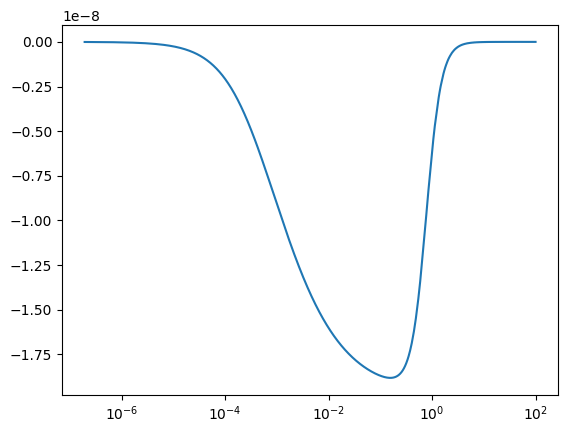

In [446]:
plt.plot(asol,constrain/T_hd)
plt.xscale("log")

In [447]:
def gi_sol(stigma, wi,mups2, a0):
    return ((-4*a0**4*stigma*(-1 + 3*wi))/(mups2*(stigma*(3 - 9*wi) - stigma**3*(1 + 3*wi)**2 + (stigma + 3*stigma*wi)**2 + (1 + 3*wi)*((-1 + stigma)**2*stigma**2*(2 - 6*wi + (stigma + 3*stigma*wi)**2))**(1/2))))

In [448]:
def gi_sol_2(stigma, wi,mups2, a0):
    return (-4*a0**4*stigma*(1 - 3*wi))/(mups2*(stigma**3*(1 + 3*wi)**2 + stigma*(-3 + 9*wi) - (stigma + 3*stigma*wi)**2 + (1 + 3*wi)*((-1 + stigma)**2*stigma**2*(2 - 6*wi + (stigma + 3*stigma*wi)**2))**(1/2)))

In [449]:
print(gi_sol(stigma, 1/3,mups2, a0), gi_sol_2(stigma, 1/3,mups2, a0),
    gi_sol(stigma, 0,mups2, a0), gi_sol_2(stigma, 0,mups2, a0),
     gi_sol(stigma, -1,mups2, a0), gi_sol_2(stigma, -1,mups2, a0))

0.0 -0.0 0.9751891856781778 0.9865918022240109 0.9865918022240106 0.9751891856781775


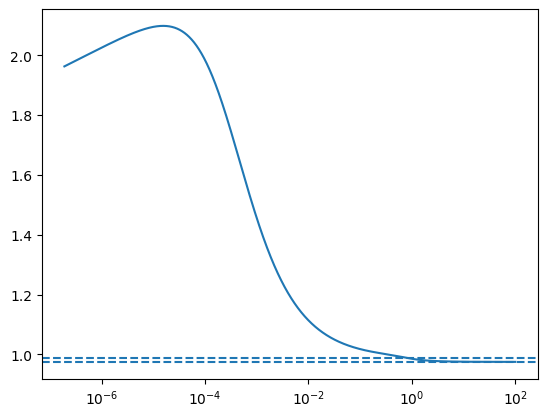

In [450]:
plt.plot(asol, Gi)
plt.axhline(gi_sol_2(stigma, 0,mups2, a0), ls="--")
plt.axhline(gi_sol_2(stigma, -1,mups2, a0), ls="--")
plt.xscale("log")

In [451]:
asol

array([1.91240097e-07, 1.91624432e-07, 1.92009542e-07, ...,
       9.95987916e+01, 9.97990764e+01, 1.00000000e+02], shape=(10000,))

In [452]:
Gsol = interp1d(asol, Gi, bounds_error=False, fill_value="extrapolate")

In [453]:
print(a0)
print(Gsol(1))

0.9725021921804177
0.9855902013333828


In [454]:
def H(a, omega_m, h):
    val = (h*100)*np.sqrt(Gsol(a)*(omega_m*(a0*a)**-3+omega_r(h)*(a0*a)**-4+OmL))
    return val

In [455]:
print(H(1, omega_m, h))
print(h)

70.00000051546286
0.7


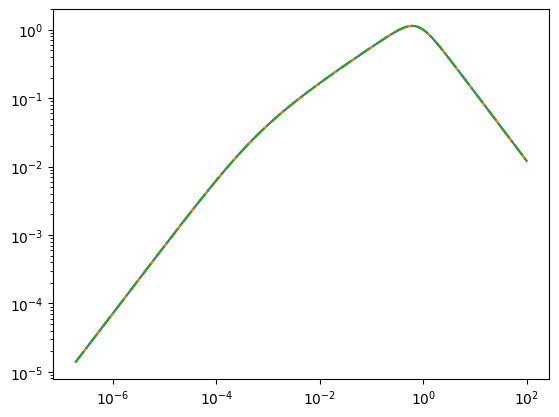

In [456]:
plt.plot(asol, h*100/(asol*H(asol, omega_m, h)))
plt.plot(asol, h*100*asol/ (a0* hsol), "--")
plt.plot(asol, h*100/(asol*((a0* hsol)/asol**2)), "-.")
plt.xscale("log")
plt.yscale("log")

In [457]:
def cpsq_plus(stigma, wi):
    val = ((stigma*(1 + 2*(-3 + stigma)*stigma + (-3 + 6*stigma*(1 + stigma))*wi) - 2*((-1 + stigma)**2*stigma**2*(2 - 6*wi + (stigma + 3*stigma*wi)**2))**(1/2))/((-1 + 4*stigma**2)*(-1 + 3*wi))) 
    return val

def cpsq_minus(stigma, wi):
    val = ((stigma*(1 + 2*(-3 + stigma)*stigma + (-3 + 6*stigma*(1 + stigma))*wi) + 2*((-1 + stigma)**2*stigma**2*(2 - 6*wi + (stigma + 3*stigma*wi)**2))**(1/2))/((-1 + 4*stigma**2)*(-1 + 3*wi)))
    return val

0.9787344375656456 0.994367218782823


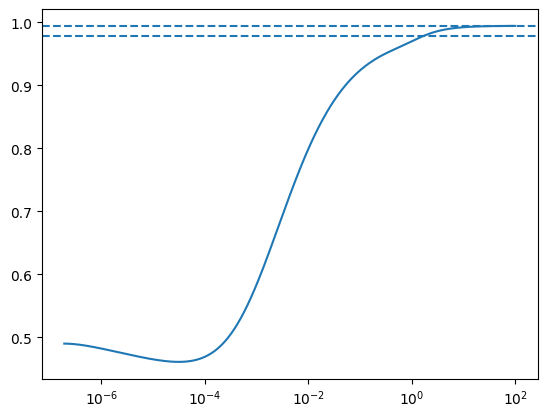

In [458]:
import matplotlib.pyplot as plt
plt.plot(asol, varpisol**2)
print(cpsq_minus(stigma, 0), cpsq_minus(stigma, -1))

plt.axhline(cpsq_minus(stigma, 0), ls = "--")

plt.axhline(cpsq_minus(stigma, -1), ls = "--")
# plt.plot(asol, cp_minus(stigma, weff),"--")
# plt.ylim(0.994, 1)


plt.xscale("log")


In [459]:
# Delete OmL and see if it goes to Omega_m constant solution

In [460]:
weff = 1/3-(2*asol*ddasol)/(3*hsol**2)

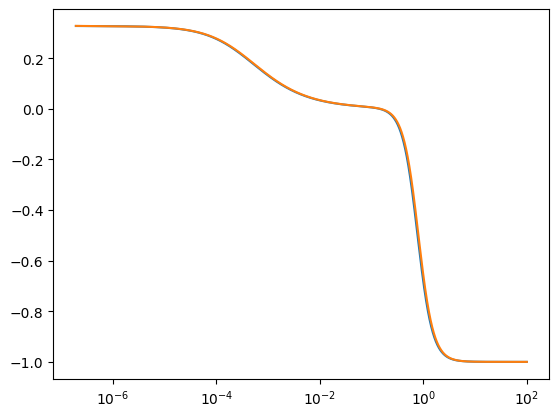

In [461]:
import matplotlib.pyplot as plt
plt.plot(asol, weff)
plt.plot(asol, weff2sol)
plt.xscale("log")

In [298]:
import camb
# --- Parameters ---
cpr     = 0.99
omega_m = 0.3
h       = 0.67
OmL     = 0.7
stigma  = 1.0
mups2   = 4/3
H0      = h * 100

# --- Solve ODE ---
asol, varpisol, hsol, dvarpisol, a0, P_DE, rho_DE, constrain = rhopsol(
    cpr, omega_m, h, OmL, stigma, mups2)

# --- Hubble horizon ---
plt.figure()
plt.plot(asol, H0*asol / (a0* hsol))
plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'$a$')
plt.ylabel(r'$H_0/(aH(a))$')
plt.title(r'Hubble horizon')
plt.tight_layout()
plt.show()

# --- CMB power spectrum ---
pars = camb.CAMBparams()
pars.set_cosmology(H0=H0, ombh2=0.02242, omch2=0.11933, mnu=0.06, omk=0, tau=0.0544)
pars.set_dark_energy_rho_p_a(a_p=asol, a_rho=asol, p=P_DE, rho=rho_DE)
pars.set_for_lmax(2500, lens_potential_accuracy=0)
pars.InitPower.set_params(As=2.1e-9, ns=0.965, r=0)

results = camb.get_results(pars)
cls = results.get_cmb_power_spectra(pars, CMB_unit='muK')['total']
ell = np.arange(cls.shape[0])

plt.figure()
plt.plot(ell, cls[:, 0])
plt.xlabel(r'$\ell$')
plt.ylabel(r'$D_\ell\;[\mu\mathrm{K}^2]$')
plt.title('CMB TT power spectrum')
plt.tight_layout()
plt.show()


[np.float64(1.261606968617901e-07), np.float64(0.9900014997676475), np.float64(0.6534796452321086), np.float64(7.76662399134816)]
0.00034591045411003327
[np.float64(1.2616708652160452e-07), np.float64(0.9900014997676475), np.float64(0.6535127420105233), np.float64(7.76662399134816)]
0.0003459148894470323


ValueError: too many values to unpack (expected 8)

In [104]:
import sys
import numpy as np
import matplotlib.pyplot as plt
import camb

sys.path.insert(0, '/Users/starfish/Desktop/PhD2025-26/distances/TorC/Stigma/python')
from equations_double import rhopsol

# --- Fixed cosmological parameters ---
cpr     = 0.99
omega_m = 0.3
h       = 0.67
OmL     = 0.7
H0      = h * 100

def solve_and_camb(stigma, mups2):
    asol, _, hsol, _, a0, P_DE, rho_DE, constrain = rhopsol(
        cpr, omega_m, h, OmL, stigma, mups2)
    pars = camb.CAMBparams()
    pars.set_cosmology(H0=H0, ombh2=0.02242, omch2=0.11933, mnu=0.06, omk=0, tau=0.0544)
    pars.set_dark_energy_rho_p_a(a_p=asol, a_rho=asol, p=P_DE, rho=rho_DE)
    pars.set_for_lmax(2500, lens_potential_accuracy=0)
    pars.InitPower.set_params(As=2.1e-9, ns=0.965, r=0)
    results = camb.get_results(pars)
    cls = results.get_cmb_power_spectra(pars, CMB_unit='muK')['total']
    ell = np.arange(cls.shape[0])
    horizon = H0 * asol / (a0 * hsol)
    return asol, horizon, ell, cls[:, 0], constrain

In [180]:
# ======================================================
base_a, base_horizon, base_ell, base_cls, constrain_base = solve_and_camb(stigma=1.0, mups2=4/3)

1.9307917635068308e-07
1.9307917635068308e-07
[np.float64(1.261606968617901e-07), np.float64(0.9900014997676475), np.float64(0.6534796452321086), np.float64(7.76662399134816)]
0.9999493555729108


1.94921187357652e-07
1.94921187357652e-07
[np.float64(1.240382983393637e-07), np.float64(0.989993170022223), np.float64(0.6364146595809747), np.float64(-35.03720322532416)]
0.9801998379760737


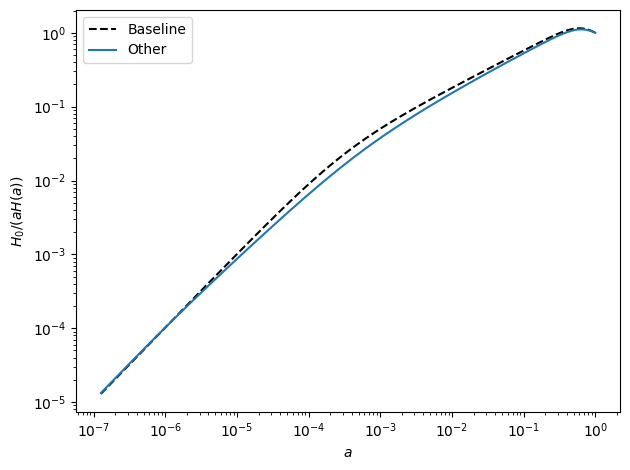

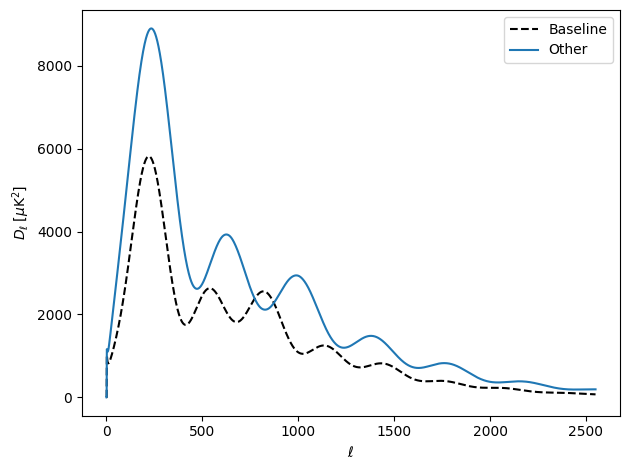

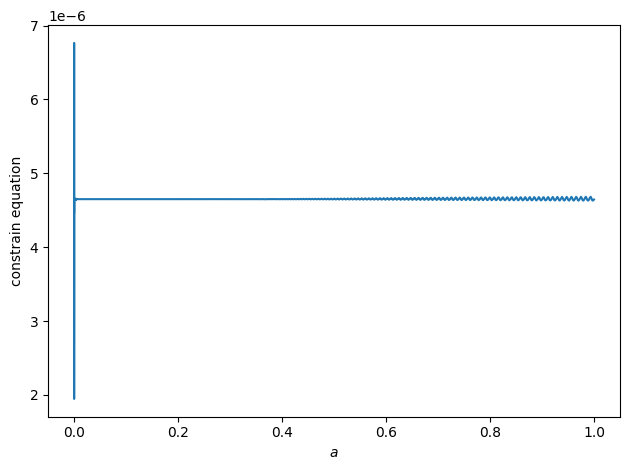

In [191]:
other_a, other_horizon, other_ell, other_cls, constrain = solve_and_camb(stigma=1.1062, mups2=4/3)

fig1, ax1 = plt.subplots()
ax1.plot(base_a,  base_horizon,  'k--', label='Baseline')
ax1.plot(other_a, other_horizon, '-',   label='Other')
ax1.set_xscale('log'); ax1.set_yscale('log')
ax1.set_xlabel(r'$a$'); ax1.set_ylabel(r'$H_0/(aH(a))$')
ax1.legend(); fig1.tight_layout()

fig2, ax2 = plt.subplots()
ax2.plot(base_ell,  base_cls,  'k--', label='Baseline')
ax2.plot(other_ell, other_cls, '-',   label='Other')
ax2.set_xlabel(r'$\ell$'); ax2.set_ylabel(r'$D_\ell\;[\mu\mathrm{K}^2]$')
ax2.legend(); fig2.tight_layout()

fig3, ax3 = plt.subplots()
ax3.plot(other_a, constrain, '-',   label='Other')
ax3.set_xlabel(r'$a$'); ax3.set_ylabel('constrain equation')
fig3.tight_layout()

plt.show()
